<a href="https://colab.research.google.com/github/varun10092004/Project_Assignment/blob/main/project_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install kagglehub transformers scikit-learn seaborn matplotlib pandas

In [2]:
import os, re, time, random, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


Download or upload the required dataset

In [3]:
import kagglehub

DATA_DIR = None
try:
    DATA_DIR = kagglehub.dataset_download("ashfakyeafi/spam-email-classification")
    print("Dataset downloaded to:", DATA_DIR)
except Exception as e:
    print("Automatic Kaggle download failed.")
    print("Use the next cell to upload the CSV downloaded from the assignment's Kaggle page.")
    print("Error type:", type(e).__name__)

Using Colab cache for faster access to the 'spam-email-classification' dataset.
Dataset downloaded to: /kaggle/input/spam-email-classification


In [4]:
# Fallback: run this cell only if automatic download failed.
from google.colab import files
uploaded = files.upload()
uploaded_names = list(uploaded.keys())
print("Uploaded files:", uploaded_names)

Uploaded files: []


Find the CSV and inspect the dataset

In [5]:
csv_files = []
if DATA_DIR and os.path.exists(DATA_DIR):
    csv_files += glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
csv_files += glob.glob("/content/*.csv")

csv_files = list(dict.fromkeys(csv_files))
print("CSV files found:")
for i, p in enumerate(csv_files):
    print(i, p)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Download the dataset from the Kaggle link in the assignment, "
        "upload the CSV to Colab, and rerun this cell."
    )

# If the first CSV is not the dataset, change this index or set the full path.
CSV_PATH = csv_files[0]
df_raw = pd.read_csv(CSV_PATH, encoding_errors="replace")
print("Selected file:", CSV_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("Columns:", df_raw.columns.tolist())
display(df_raw.isna().sum().to_frame("missing_values"))

CSV files found:
0 /kaggle/input/spam-email-classification/email.csv
Selected file: /kaggle/input/spam-email-classification/email.csv
Shape: (5573, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Columns: ['Category', 'Message']


,missing_values
Category,0
Message,0


Identify the email-text and label columns

In [6]:
def norm_col(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())

text_candidates = ["text", "email", "message", "emailtext", "body", "content", "mail"]
label_candidates = ["label", "category", "class", "target", "spam", "type", "classification"]

TEXT_COL = next((c for c in df_raw.columns if norm_col(c) in text_candidates), None)
LABEL_COL = next((c for c in df_raw.columns if norm_col(c) in label_candidates and c != TEXT_COL), None)

print("Automatically selected text column:", TEXT_COL)
print("Automatically selected label column:", LABEL_COL)
print("Available columns:", df_raw.columns.tolist())

# If either value is None or incorrect, uncomment and edit these two lines:
# TEXT_COL = "exact_text_column_name"
# LABEL_COL = "exact_label_column_name"

if TEXT_COL is None or LABEL_COL is None:
    raise ValueError("Set TEXT_COL and LABEL_COL manually using the exact column names shown above.")

display(df_raw[[TEXT_COL, LABEL_COL]].head(10))
print("Original label values:")
print(df_raw[LABEL_COL].astype(str).str.strip().value_counts().head(30))

Automatically selected text column: Message
Automatically selected label column: Category
Available columns: ['Category', 'Message']


,Message,Category
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham
5,FreeMsg Hey there darling it's been 3 week's n...,spam
6,Even my brother is not like to speak with me. ...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,ham
8,WINNER!! As a valued network customer you have...,spam
9,Had your mobile 11 months or more? U R entitle...,spam


Original label values:
Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64


Finding the invalid row

In [7]:
display(df_raw[df_raw["Category"].astype(str).str.strip() == '{"mode":"full"'])

,Category,Message
5572,"{""mode"":""full""",isActive:false}


Clean the dataset and map labels to Ham/Spam

In [8]:

import numpy as np
import pandas as pd

TEXT_COL = "Message"
LABEL_COL = "Category"

data = df_raw[[TEXT_COL, LABEL_COL]].copy()
data.columns = ["text", "label"]

data = data.dropna(subset=["text", "label"])
data["text"] = data["text"].astype(str).str.strip()
data["label"] = data["label"].astype(str).str.strip().str.lower()

data = data[
    (data["text"].str.len() > 0) &
    (data["label"].isin(["ham", "spam"]))
].copy()

data = data.drop_duplicates(subset=["text"]).reset_index(drop=True)

data["y"] = data["label"].map({
    "ham": 0,
    "spam": 1
}).astype(int)

print("Cleaned shape:", data.shape)
print("\nClass distribution:")
print(data["label"].value_counts())

print("\nLabel mapping: 0 = Ham, 1 = Spam")
display(data.head())


Cleaned shape: (5157, 3)

Class distribution:
label
ham     4516
spam     641
Name: count, dtype: int64

Label mapping: 0 = Ham, 1 = Spam


,text,label,y
0,"Go until jurong point, crazy.. Available only ...",ham,0
1,Ok lar... Joking wif u oni...,ham,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam,1
3,U dun say so early hor... U c already then say...,ham,0
4,"Nah I don't think he goes to usf, he lives aro...",ham,0


Explore class distribution and email lengths

,count
y,
Ham,4516
Spam,641


Class percentages:


,percent
y,
Ham,87.57
Spam,12.43


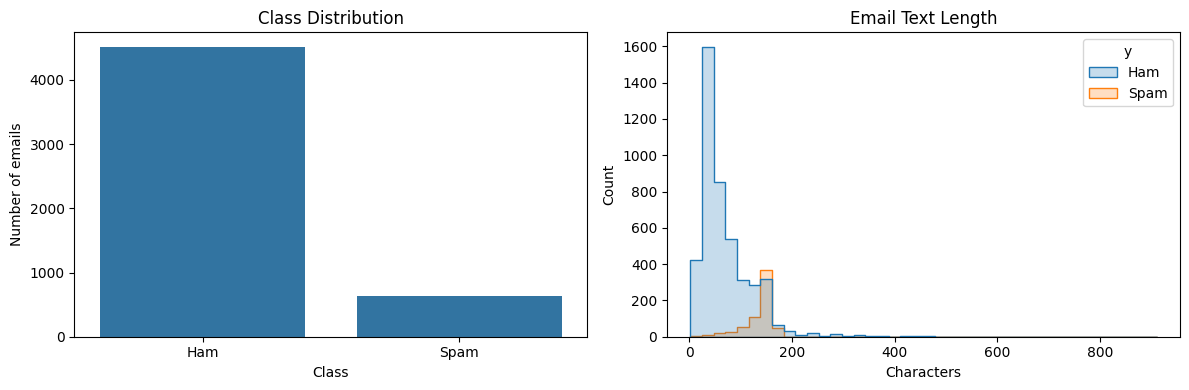

In [9]:
class_counts = data["y"].map({0:"Ham", 1:"Spam"}).value_counts().reindex(["Ham", "Spam"], fill_value=0)
display(class_counts.to_frame("count"))
print("Class percentages:")
display((100 * class_counts / class_counts.sum()).round(2).to_frame("percent"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax[0])
ax[0].set_title("Class Distribution")
ax[0].set_xlabel("Class")
ax[0].set_ylabel("Number of emails")

data["text_length"] = data["text"].str.len()
sns.histplot(data=data, x="text_length", hue=data["y"].map({0:"Ham", 1:"Spam"}),
             bins=40, element="step", stat="count", common_norm=False, ax=ax[1])
ax[1].set_title("Email Text Length")
ax[1].set_xlabel("Characters")
ax[1].set_ylabel("Count")
plt.tight_layout()
plt.savefig("dataset_exploration.png", dpi=200, bbox_inches="tight")
plt.show()

Train/test split

In [10]:
X = data["text"].astype(str).to_numpy()
y = data["y"].to_numpy()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, random_state=SEED, stratify=y_train_full
)

print(f"Train: {len(X_train)} ({len(X_train)/len(X):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(X):.1%})")
print(f"Test: {len(X_test)} ({len(X_test)/len(X):.1%})")
print("Train label proportions:", pd.Series(y_train).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test label proportions:", pd.Series(y_test).value_counts(normalize=True).sort_index().round(3).to_dict())

Train: 3712 (72.0%)
Validation: 413 (8.0%)
Test: 1032 (20.0%)
Train label proportions: {0: 0.876, 1: 0.124}
Test label proportions: {0: 0.876, 1: 0.124}


Part A — Traditional Machine Learning  
TF-IDF + Logistic Regression and Naive Bayes

In [11]:
def clean_for_tfidf(s):
    # Keep words, numbers, and useful punctuation; lowercase and normalize spaces.
    s = str(s).lower()
    s = re.sub(r"\s+", " ", s)
    return s.strip()

X_train_classic = [clean_for_tfidf(s) for s in X_train]
X_val_classic = [clean_for_tfidf(s) for s in X_val]
X_test_classic = [clean_for_tfidf(s) for s in X_test]

vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    strip_accents="unicode"
)
t0 = time.perf_counter()
Xtr_vec = vectorizer.fit_transform(X_train_classic)
Xte_vec = vectorizer.transform(X_test_classic)
tfidf_fit_time = time.perf_counter() - t0
print("TF-IDF training matrix:", Xtr_vec.shape)
print("TF-IDF transform + fit time (seconds):", round(tfidf_fit_time, 2))

TF-IDF training matrix: (3712, 9164)
TF-IDF transform + fit time (seconds): 0.19


In [12]:
def metric_row(name, y_true, y_pred, elapsed):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Training time (seconds)": elapsed
    }

classic_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=None, random_state=SEED),
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0)
}
results = []
predictions = {}
conf_mats = {}
classic_times = {}

for name, model in classic_models.items():
    start = time.perf_counter()
    model.fit(Xtr_vec, y_train)
    train_time = time.perf_counter() - start
    pred = model.predict(Xte_vec)
    results.append(metric_row(name, y_test, pred, train_time))
    predictions[name] = pred
    conf_mats[name] = confusion_matrix(y_test, pred, labels=[0, 1])
    classic_times[name] = train_time
    print("\n", name)
    print(classification_report(y_test, pred, labels=[0,1], target_names=["Ham", "Spam"], zero_division=0))

results_df = pd.DataFrame(results)
display(results_df.round(4))


 Logistic Regression
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.70      0.82       128

    accuracy                           0.96      1032
   macro avg       0.98      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032


 Multinomial Naive Bayes
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.69      0.81       128

    accuracy                           0.96      1032
   macro avg       0.98      0.84      0.90      1032
weighted avg       0.96      0.96      0.96      1032



,Model,Accuracy,Precision,Recall,F1-score,Training time (seconds)
0,Logistic Regression,0.9622,1.0,0.6953,0.8203,0.0416
1,Multinomial Naive Bayes,0.9612,1.0,0.6875,0.8148,0.0031


Get your Hugging Face token

In [13]:
from huggingface_hub import notebook_login

notebook_login()

Run your tokenizer code again

In [14]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!


Part B — Transformer Model  
Tokenize text for DistilBERT

In [15]:
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, DistilBertForSequenceClassification, get_linear_schedule_with_warmup

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 3
LR = 2e-5
WEIGHT_DECAY = 0.01

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class EmailDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

train_ds = EmailDataset(X_train, y_train, tokenizer, MAX_LEN)
val_ds = EmailDataset(X_val, y_val, tokenizer, MAX_LEN)
test_ds = EmailDataset(X_test, y_test, tokenizer, MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader), "| Validation batches:", len(val_loader), "| Test batches:", len(test_loader))

Train batches: 232 | Validation batches: 26 | Test batches: 65


Custom PyTorch training loop

In [16]:
model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0:"Ham", 1:"Spam"},
    label2id={"Ham":0, "Spam":1}
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

def run_eval(model, loader):
    model.eval()
    total_loss, total_n = 0.0, 0
    all_y, all_pred = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k:v.to(device) for k,v in batch.items()}
            out = model(**batch)
            n = batch["labels"].size(0)
            total_loss += out.loss.item() * n
            total_n += n
            preds = torch.argmax(out.logits, dim=1)
            all_y.extend(batch["labels"].cpu().numpy().tolist())
            all_pred.extend(preds.cpu().numpy().tolist())
    return total_loss / max(total_n, 1), np.array(all_y), np.array(all_pred)

history = {"train_loss": [], "val_loss": [], "val_f1": []}
bert_start = time.perf_counter()

for epoch in range(EPOCHS):
    model.train()
    running_loss, seen = 0.0, 0
    for batch in train_loader:
        batch = {k:v.to(device) for k,v in batch.items()}
        optimizer.zero_grad()
        out = model(**batch)
        loss = out.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        n = batch["labels"].size(0)
        running_loss += loss.item() * n
        seen += n

    train_loss = running_loss / max(seen, 1)
    val_loss, val_true, val_pred = run_eval(model, val_loader)
    val_f1 = f1_score(val_true, val_pred, pos_label=1, zero_division=0)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | val spam-F1={val_f1:.4f}")

bert_train_time = time.perf_counter() - bert_start
print("DistilBERT training time (seconds):", round(bert_train_time, 2))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | train loss=0.1604 | val loss=0.0114 | val spam-F1=0.9903
Epoch 2/3 | train loss=0.0298 | val loss=0.0081 | val spam-F1=0.9901
Epoch 3/3 | train loss=0.0140 | val loss=0.0036 | val spam-F1=0.9903
DistilBERT training time (seconds): 131.71


Evaluate DistilBERT on the held-out test set

In [17]:
test_loss, bert_y_true, bert_y_pred = run_eval(model, test_loader)
results.append(metric_row("DistilBERT", bert_y_true, bert_y_pred, bert_train_time))
predictions["DistilBERT"] = bert_y_pred
conf_mats["DistilBERT"] = confusion_matrix(bert_y_true, bert_y_pred, labels=[0, 1])
results_df = pd.DataFrame(results)
display(results_df.round(4))
print(classification_report(bert_y_true, bert_y_pred, labels=[0,1], target_names=["Ham", "Spam"], zero_division=0))

,Model,Accuracy,Precision,Recall,F1-score,Training time (seconds)
0,Logistic Regression,0.9622,1.0000,0.6953,0.8203,0.0416
1,Multinomial Naive Bayes,0.9612,1.0000,0.6875,0.8148,0.0031
2,DistilBERT,0.9874,0.9832,0.9141,0.9474,131.7066


              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.98      0.91      0.95       128

    accuracy                           0.99      1032
   macro avg       0.99      0.96      0.97      1032
weighted avg       0.99      0.99      0.99      1032



Visualizations  
Compare all evaluation metrics

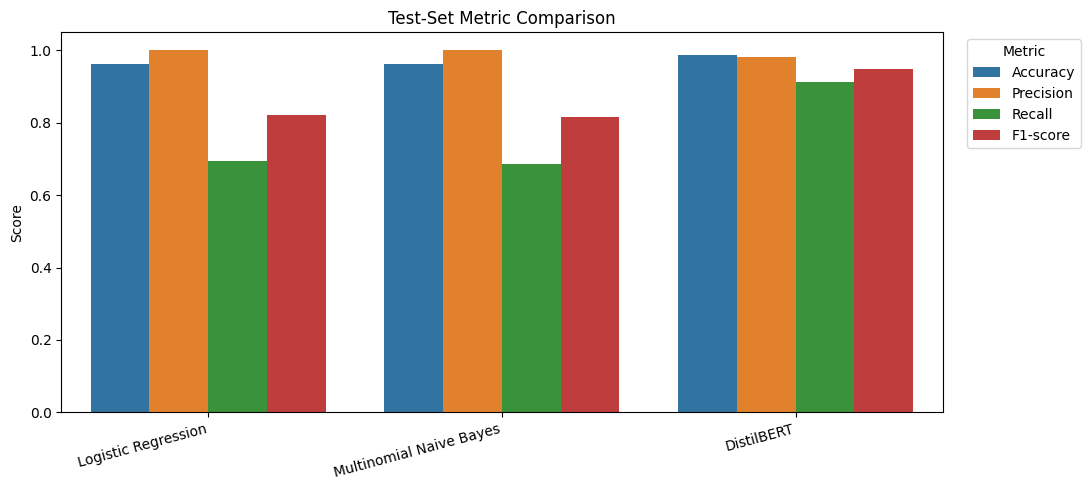

In [18]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df.melt(id_vars="Model", value_vars=metric_cols, var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title("Test-Set Metric Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

Confusion matrices

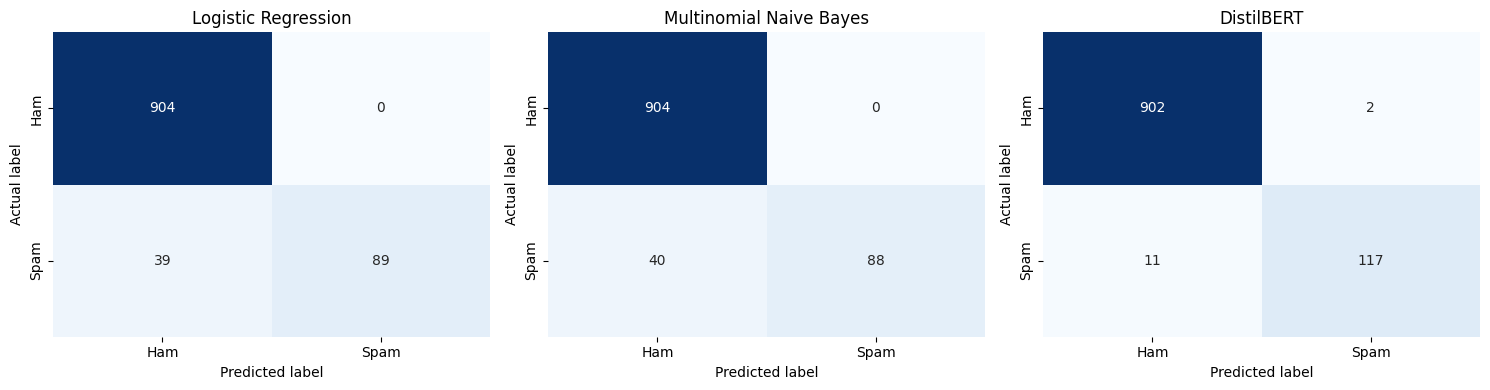

In [19]:
fig, axes = plt.subplots(1, len(conf_mats), figsize=(5 * len(conf_mats), 4))
if len(conf_mats) == 1:
    axes = [axes]
for ax, (name, cm) in zip(axes, conf_mats.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

DistilBERT training behavior

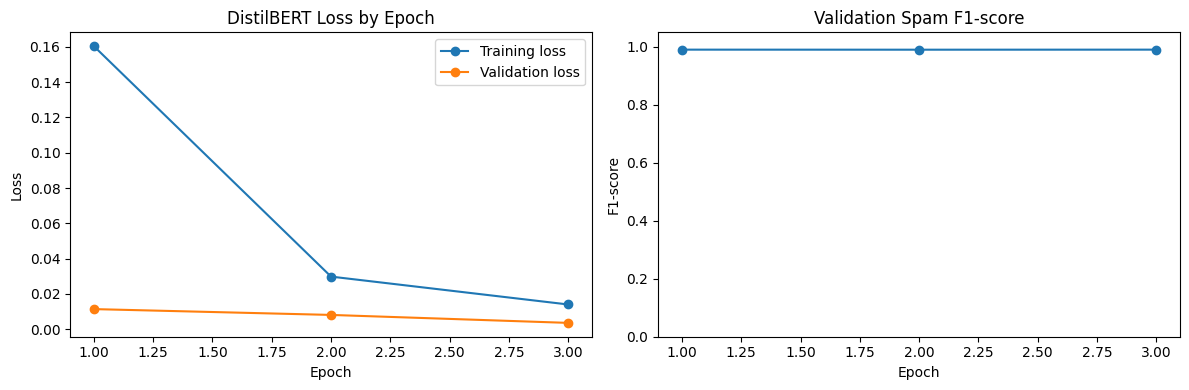

In [20]:
epochs_axis = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs_axis, history["train_loss"], marker="o", label="Training loss")
ax[0].plot(epochs_axis, history["val_loss"], marker="o", label="Validation loss")
ax[0].set_title("DistilBERT Loss by Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs_axis, history["val_f1"], marker="o")
ax[1].set_title("Validation Spam F1-score")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("F1-score")
ax[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("distilbert_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

Compare computational cost

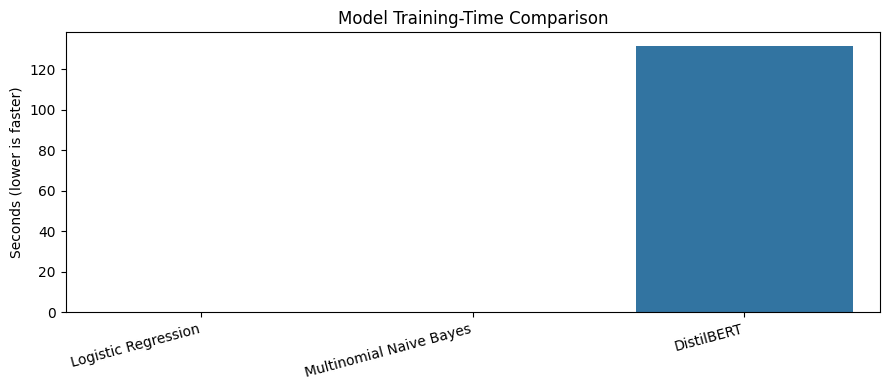

Shared TF-IDF fit time (seconds): 0.19


,Model,Training time (seconds)
0,Logistic Regression,0.04
1,Multinomial Naive Bayes,0.00
2,DistilBERT,131.71


In [21]:
time_df = results_df[["Model", "Training time (seconds)"]].copy()
plt.figure(figsize=(9, 4))
sns.barplot(data=time_df, x="Model", y="Training time (seconds)")
plt.title("Model Training-Time Comparison")
plt.xlabel("")
plt.ylabel("Seconds (lower is faster)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("training_time_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Shared TF-IDF fit time (seconds):", round(tfidf_fit_time, 2))
display(time_df.round(2))

Save results and plots for the report

In [22]:
results_df.to_csv("model_results.csv", index=False)
pd.DataFrame(history).to_csv("distilbert_training_history.csv", index=False)
print("Saved: model_results.csv, distilbert_training_history.csv")
print("Saved plots: dataset_exploration.png, metric_comparison.png, confusion_matrices.png, distilbert_training_curves.png, training_time_comparison.png")

Saved: model_results.csv, distilbert_training_history.csv
Saved plots: dataset_exploration.png, metric_comparison.png, confusion_matrices.png, distilbert_training_curves.png, training_time_comparison.png


Automatically create a results summary

In [23]:
display(results_df.sort_values("F1-score", ascending=False).round(4))
best_f1 = results_df.loc[results_df["F1-score"].idxmax()]
print(f"Highest test Spam F1-score in this run: {best_f1['Model']} ({best_f1['F1-score']:.4f})")
print("This result applies only to this dataset split, preprocessing, hyperparameters, and runtime.")

,Model,Accuracy,Precision,Recall,F1-score,Training time (seconds)
2,DistilBERT,0.9874,0.9832,0.9141,0.9474,131.7066
0,Logistic Regression,0.9622,1.0000,0.6953,0.8203,0.0416
1,Multinomial Naive Bayes,0.9612,1.0000,0.6875,0.8148,0.0031


Highest test Spam F1-score in this run: DistilBERT (0.9474)
This result applies only to this dataset split, preprocessing, hyperparameters, and runtime.
